Convert `BGR` to Grayscale by `Lunimance`
$$
I_gray = 0.299R + 0.587G + 0.144B
$$
Non-Linear `Gamma` $I_{out} = c \times I_{in}^{\gamma}$

In [1]:
def luminance(R, G, B):
    return int(0.299 * R + 0.587 * G + 0.144 * B)

pixel = (200, 150, 100)
I_grey = luminance(pixel[0], pixel[1], pixel[2])
I_grey

162

In [2]:
def gamma_convert(grey_scale, gamma):
    return (grey_scale / 255) ** gamma

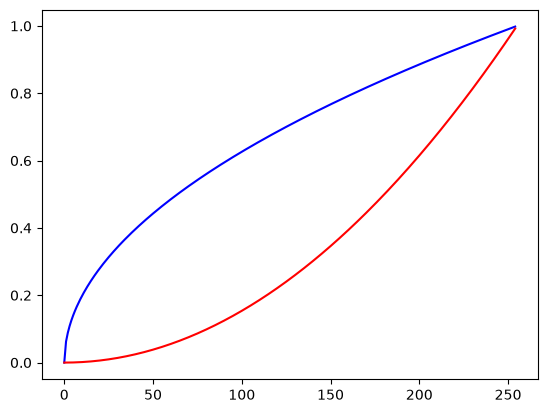

In [3]:
gamma_a = 0.5
gamma_b = 2.0
grey_a = []
grey_b = []

for i in range(255):
    grey_a.append(gamma_convert(i, gamma_a))
    grey_b.append(gamma_convert(i, gamma_b))

import matplotlib.pyplot as plt
import numpy as np

plt.plot(np.arange(255), grey_a, color = "blue", label = "0.5")
plt.plot(np.arange(255), grey_b, color = "red", label = "2.0")
plt.show()

In [4]:
import tensorflow as tf
from tensorflow import keras

cifar100 = tf.keras.datasets.cifar10

I0000 00:00:1791031288.071378  115970 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791031288.090722  115970 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791031289.047780  115970 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791031292.820668  115970 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [5]:
(x_train, y_train), (x_val, y_val) = cifar100.load_data()

In [6]:
sample = x_train[0]
sample

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]

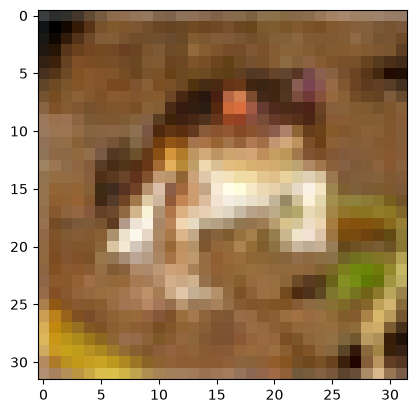

In [7]:
plt.imshow(sample)
plt.show()

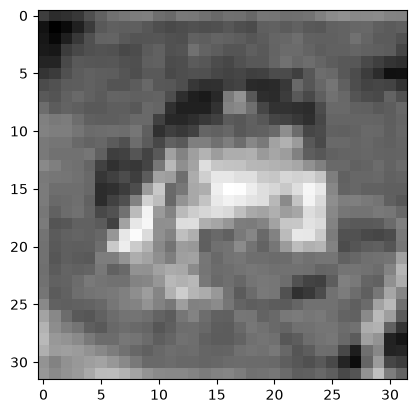

In [22]:
# Vectorization
vector_luminance =  np.array([0.299, 0.587, 0.114]) 
vector_grey_scale = np.dot(sample[..., :3], vector_luminance)
vector_grey_scale = np.array(vector_grey_scale, dtype=np.uint8)
plt.imshow(vector_grey_scale, cmap = "gray")
plt.show()

In [35]:
vector_grey_scale.shape

(32, 32)

In [23]:
flatten_grey_scale = vector_grey_scale.flatten()

(array([ 9., 22., 24., 25., 25., 23., 24., 20., 13., 12.]),
 array([  0. ,  25.1,  50.2,  75.3, 100.4, 125.5, 150.6, 175.7, 200.8,
        225.9, 251. ]),
 <BarContainer object of 10 artists>)

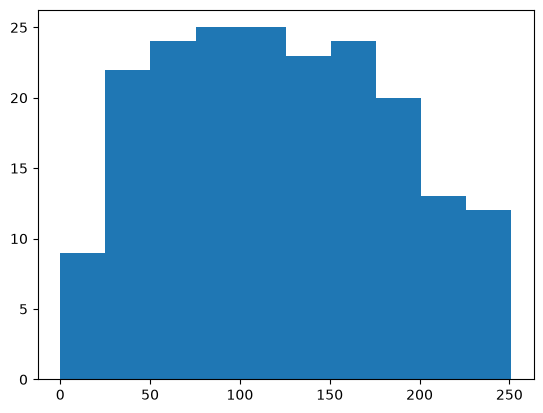

In [24]:
values, counts = np.unique(flatten_grey_scale, return_counts=True)
counter = dict(zip(values, counts))
import pandas as pd
plt.hist(counter)

In [53]:
# 1. Tính Histogram: Đếm số lượng pixel cho từng mức xám (từ 0 đến 255)
# Sử dụng range=[0, 256] để bao phủ đủ 256 mức xám
hist, bins = np.histogram(vector_grey_scale, bins=256, range=[0, 256])

# 2. Tính CDF bằng cách cộng dồn (Cumulative Sum) mảng đếm tần suất
CDF_LIST = hist.cumsum()

# Lúc này, phần tử cuối cùng CDF_LIST[-1] sẽ bằng chính xác tổng số pixel của ảnh
print(CDF_LIST)

[   1    1    1    1    1    1    1    1    2    2    3    3    3    4
    4    4    5    6    7    7    7    7    8   10   10   10   12   12
   12   12   13   15   18   19   20   21   23   24   25   26   28   29
   31   32   34   37   40   44   48   51   55   55   58   59   61   63
   68   69   71   74   76   79   84   86   90   95  101  102  104  110
  114  118  124  128  133  143  146  153  158  166  172  180  181  189
  197  204  220  229  238  250  270  282  296  311  334  351  373  401
  424  442  466  485  501  517  536  551  565  581  596  606  618  637
  652  667  679  692  710  722  728  735  745  751  755  762  769  774
  781  783  791  798  804  806  809  812  818  824  829  834  834  835
  838  841  845  848  851  854  860  860  863  864  869  872  877  879
  884  886  890  891  894  900  901  906  907  910  911  914  916  916
  917  919  924  927  930  932  935  937  941  941  943  945  946  949
  952  954  957  958  960  960  963  963  963  964  964  967  968  971
  972 

In [54]:
sorted_CDF  = sorted(CDF_LIST, reverse=False)
sorted_CDF

[np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(2),
 np.int64(2),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(4),
 np.int64(4),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(7),
 np.int64(7),
 np.int64(7),
 np.int64(8),
 np.int64(10),
 np.int64(10),
 np.int64(10),
 np.int64(12),
 np.int64(12),
 np.int64(12),
 np.int64(12),
 np.int64(13),
 np.int64(15),
 np.int64(18),
 np.int64(19),
 np.int64(20),
 np.int64(21),
 np.int64(23),
 np.int64(24),
 np.int64(25),
 np.int64(26),
 np.int64(28),
 np.int64(29),
 np.int64(31),
 np.int64(32),
 np.int64(34),
 np.int64(37),
 np.int64(40),
 np.int64(44),
 np.int64(48),
 np.int64(51),
 np.int64(55),
 np.int64(55),
 np.int64(58),
 np.int64(59),
 np.int64(61),
 np.int64(63),
 np.int64(68),
 np.int64(69),
 np.int64(71),
 np.int64(74),
 np.int64(76),
 np.int64(79),
 np.int64(84),
 np.int64(86),
 np.int64(90),
 np.int64(95),
 np.int64(101),
 np.int64(102),
 

In [55]:
len(sorted_CDF)

256

In [56]:
minCDF = CDF_LIST[0]
normalized_grey_scale  = (CDF_LIST -  minCDF) / (32*32 - minCDF) * 255

In [57]:
normalized_grey_scale.shape

(256,)

(array([47., 18.,  7.,  5.,  5.,  7.,  7., 18., 32., 51.]),
 array([  0. ,  25.5,  51. ,  76.5, 102. , 127.5, 153. , 178.5, 204. ,
        229.5, 255. ]),
 <BarContainer object of 10 artists>)

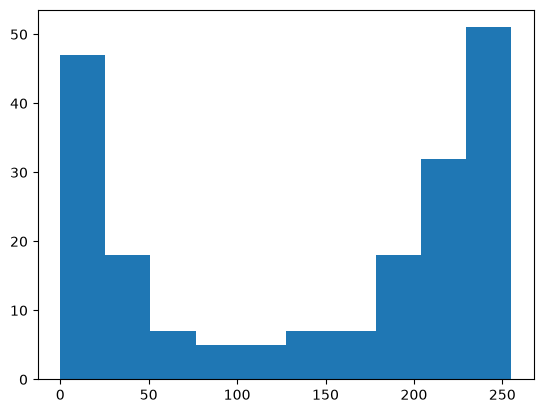

In [60]:
values, counts = np.unique(normalized_grey_scale, return_counts=True)
counter = dict(zip(values, counts))
import pandas as pd
plt.hist(counter)

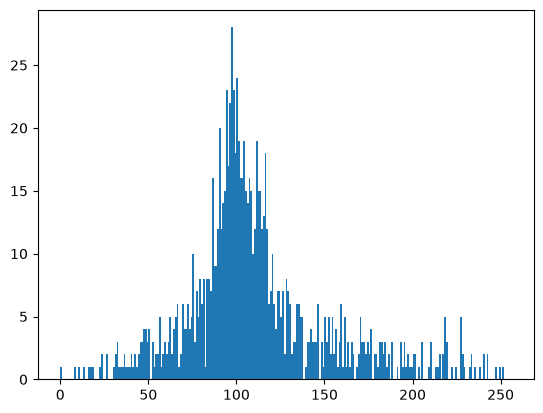

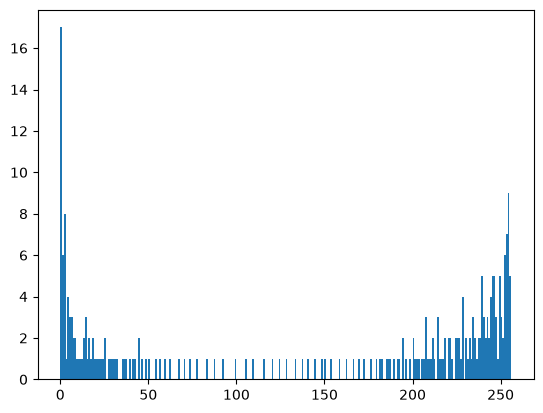

In [62]:
# Vẽ Histogram cho ảnh gốc
plt.hist(vector_grey_scale.flatten(), bins=256, range=[0, 256])
plt.show()

# Vẽ Histogram cho ảnh sau khi đã cân bằng (thay tên biến cho đúng)
plt.hist(normalized_grey_scale.flatten(), bins=256, range=[0, 256])
plt.show()

In [63]:
normalized_grey_scale

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       2.49266862e-01, 2.49266862e-01, 4.98533724e-01, 4.98533724e-01,
       4.98533724e-01, 7.47800587e-01, 7.47800587e-01, 7.47800587e-01,
       9.97067449e-01, 1.24633431e+00, 1.49560117e+00, 1.49560117e+00,
       1.49560117e+00, 1.49560117e+00, 1.74486804e+00, 2.24340176e+00,
       2.24340176e+00, 2.24340176e+00, 2.74193548e+00, 2.74193548e+00,
       2.74193548e+00, 2.74193548e+00, 2.99120235e+00, 3.48973607e+00,
       4.23753666e+00, 4.48680352e+00, 4.73607038e+00, 4.98533724e+00,
       5.48387097e+00, 5.73313783e+00, 5.98240469e+00, 6.23167155e+00,
       6.73020528e+00, 6.97947214e+00, 7.47800587e+00, 7.72727273e+00,
       8.22580645e+00, 8.97360704e+00, 9.72140762e+00, 1.07184751e+01,
       1.17155425e+01, 1.24633431e+01, 1.34604106e+01, 1.34604106e+01,
       1.42082111e+01, 1.44574780e+01, 1.49560117e+01, 1.54545455e+01,
      

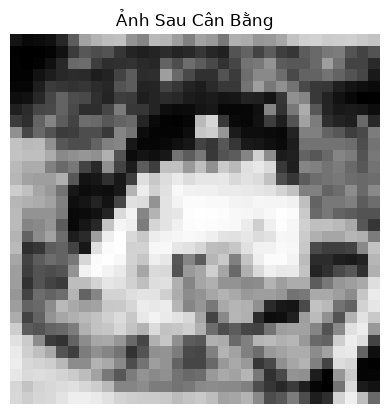

In [68]:
# 1. Ép kiểu bảng ánh xạ về số nguyên (bạn đã làm đúng bước này)
normalized_grey_scale = normalized_grey_scale.astype(np.uint8)

# 2. BƯỚC QUAN TRỌNG: Áp dụng bảng ánh xạ vào ảnh gốc để tạo ảnh mới
# Kỹ thuật này gọi là "fancy indexing" trong NumPy
equalized_image = normalized_grey_scale[vector_grey_scale]

# Bây giờ equalized_image đã tự động có shape là (32, 32) giống hệt vector_grey_scale
# Bạn có thể in nó ra ngay lập tức
import matplotlib.pyplot as plt

plt.imshow(equalized_image, cmap='gray')
plt.title("Ảnh Sau Cân Bằng")
plt.axis('off')
plt.show()